In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from matplotlib import gridspec
from pyproj import Proj, Transformer
import math
import datetime
from netCDF4 import Dataset

In [2]:
def lonlat_to_xy(coords_1, coords_2, hemisphere, inverse=False):

    """Converts between longitude/latitude and EASE xy coordinates.
 
    Args:
        lon (float): WGS84 longitude
        lat (float): WGS84 latitude
        hemisphere (string): 'n' or 's'
        inverse (bool): if true, converts xy to lon/lat
 
    Returns:
        tuple: pair of xy or lon/lat values
    """

    EASE_Proj = {'n': 'EPSG:3408',
                 's': 'EPGS:3409'}
    
    WGS_Proj = 'EPSG:4326'
    
    for coords in [coords_1, coords_2]: assert isinstance(coords,(np.ndarray,list))

    if inverse == False: # lonlat to xy
        
        lon, lat = coords_1, coords_2
        
        transformer = Transformer.from_crs(WGS_Proj, EASE_Proj[hemisphere])
        
        x, y = transformer.transform(lat, lon)
        
        return (x, y)

    else: # xy to lonlat
        
        x, y = coords_1, coords_2
        
        transformer = Transformer.from_crs(EASE_Proj[hemisphere], WGS_Proj)
        
        lat, lon = transformer.transform(x, y)
        
        return (lon, lat)

### load location data 

In [3]:
### make GPS dataframe
datapath_collars = '/Users/carmennab/Dropbox/pb_new/data/bears/data_combined.csv'

data = pd.read_csv(datapath_collars,usecols=['ID','longitude','latitude','date','sex','age']).dropna()

datetimes = [datetime.datetime.strptime(date,'%Y-%m-%d') for date in data['date']]
data['date'] = datetimes

bear_x,bear_y = lonlat_to_xy(np.array(data['longitude']),np.array(data['latitude']),hemisphere='n')

data['x'] = bear_x ; data['y'] = bear_y

In [4]:
IDs = [ID for ID in set(data['ID'])]

### calculate step lengths for each bear

In [5]:
step_distances = [] ; steps_df = []
for ID in IDs:
    bear_data = data[data['ID']==ID]

    xs = np.array(bear_data['x'])
    ys = np.array(bear_data['y'])
    dates = np.array(bear_data['date'])
    
    for c in np.arange(0,len(xs)-1):
        x1 = xs[c] ; x2 = xs[c+1] ; y1 = ys[c] ; y2 = ys[c+1] 
        d = math.sqrt((x2-x1)**2 + (y2-y1)**2)
        
        if d < 160_000: ### mask out anything over 40km/hour (max running speed)
            step_distances.append(d/1000)
            steps_df.append({'date':dates[c],'step_distance (m)':d,'ID':ID})
        
step_distances = np.array(step_distances) 

steps_df = pd.DataFrame(steps_df)   
steps_df.to_csv('/Users/carmennab/Dropbox/pb_new/scripts/SSF/step_distances.csv',index=False) ### save distance for SSF

### calculate turning angles for each bear

In [6]:
angles = [] ; angles_df = []
for ID in IDs:
    bear_data = data[data['ID']==ID]
    
    xs = np.array(bear_data['x'])
    ys = np.array(bear_data['y'])
    dates = np.array(bear_data['date'])
    
    for count in np.arange(0,len(xs)-2):
        a = [xs[count-2],ys[count-2]] 
        b = [xs[count-1],ys[count-1]] 
        c = [xs[count],ys[count]]

        ab = np.mod((180/math.pi)*math.atan2(b[0]-a[0],
                                             b[1]-a[1]),
                    360)
    
        bc = np.mod((180/math.pi)*math.atan2(c[0]-b[0], #delta_x
                                             c[1]-b[1]), #delta_y
                    360)
        
        angle = np.mod(bc-ab,360) # +ve when clockwise
        
        if angle > 180:
            angle = angle - 360
        
        angles.append(angle) ; angles_df.append({'date':dates[count],'angle':angle,'ID':ID})
        
angles_df = pd.DataFrame(angles_df)   
angles_df.to_csv('/Users/carmennab/Dropbox/pb_new/scripts/SSF/turning_angles.csv',index=False) ### save angles for SSF

### plot figure

In [7]:
figpath = '/Users/carmennab/Dropbox/Apps/Overleaf/CRiceS_PolarBears_HB/figures/'

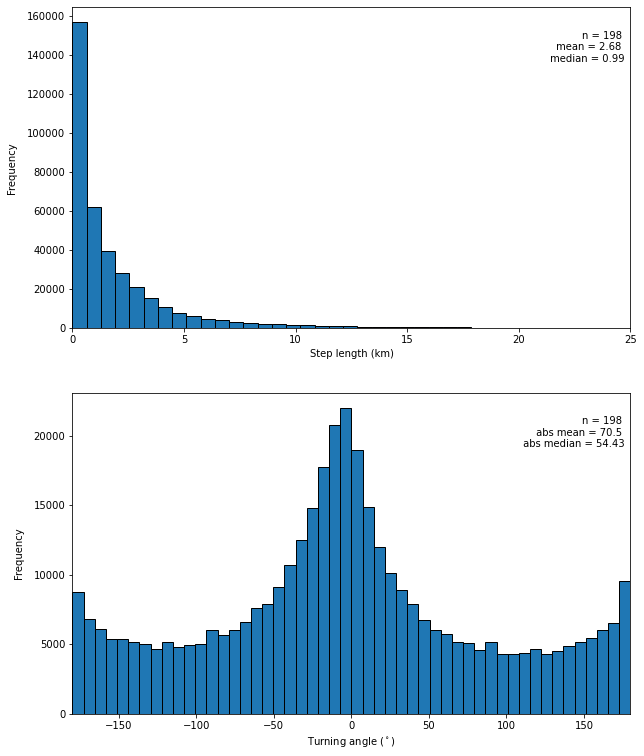

In [8]:
plt.rc('font', size=15)
fig = plt.figure(figsize=(10,13))
spec = gridspec.GridSpec(ncols=1, nrows=2,hspace=0.2)

### step lengths
n = len(IDs)
mean = np.round(np.nanmean(step_distances),decimals=2)
median = np.round(np.nanmedian(step_distances),decimals=2)

ax = fig.add_subplot(spec[0])
ax.hist(step_distances,bins=250,edgecolor='k')
ax.set_xlim([0,25])
ax.set_ylabel('Frequency',labelpad=10)
ax.set_xlabel('Step length (km)')
ax.text(0.99, 0.83,f'n = {n} \n mean = {mean} \n median = {median}',ha='right',transform = ax.transAxes)

### angles
n = len(IDs)
mean = np.round(np.nanmean(np.abs(angles)),decimals=2)
median = np.round(np.nanmedian(np.abs(angles)),decimals=2)

ax = fig.add_subplot(spec[1])
ax.hist(angles,bins=50,edgecolor='k')
ax.set_xlim([-180,180])
ax.set_ylabel('Frequency',labelpad=10)
ax.set_xlabel('Turning angle ($^\circ$)')
ax.text(0.99, 0.83,f'n = {n} \n abs mean = {mean} \n abs median = {median}',ha='right',transform = ax.transAxes)
plt.savefig(f'{figpath}step_distances_angles.jpg',bbox_inches = "tight", dpi = 200)